<a href="https://colab.research.google.com/github/Vachana7/4IK25CS228_DAV_LAB/blob/main/4IK25CS228_EXP_10.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt

In [ ]:
df=pd.read_csv('/content/House_Price_dataset.csv')
df=df[df['purpose']=='For Sale'].copy()
df['Area']=df['Area Size']
df.loc[df['Area Type']=='Kanal','Area']=df['Area Size']*20
df=df[(df['Area']>0)&(df['price']>0)]
df=df[(df['Area']<df['Area'].quantile(0.99))&(df['price']<df['price'].quantile(0.99))]
df=df.sample(n=2000,random_state=42).copy()
X=df[['Area','price']]
scaler=StandardScaler()
X_scaled=scaler.fit_transform(X)

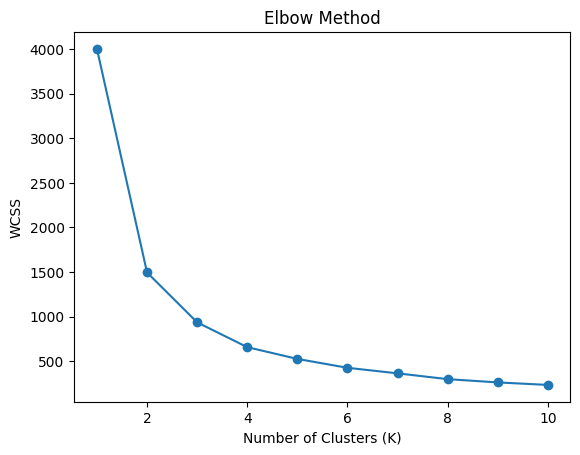

In [ ]:
wcss = []
for k in range(1, 11):
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    km.fit(X_scaled)
    wcss.append(km.inertia_)

plt.plot(range(1, 11), wcss, marker='o')
plt.xlabel('Number of Clusters (K)')
plt.ylabel('WCSS')
plt.title('Elbow Method')
plt.show()

In [ ]:
kMeans=KMeans(n_clusters=4,random_state=42,n_init=10)
df['Cluster']=kMeans.fit_predict(X_scaled)
print(df['Cluster'].value_counts().sort_index())
print(df.groupby('Cluster')[['Area','price']].mean())

Cluster
0     515
1      67
2    1159
3     259
Name: count, dtype: int64
              Area         price
Cluster                         
0        10.074951  2.492090e+07
1        29.995522  1.334701e+08
2         4.649612  8.522018e+06
3        20.453668  5.465521e+07


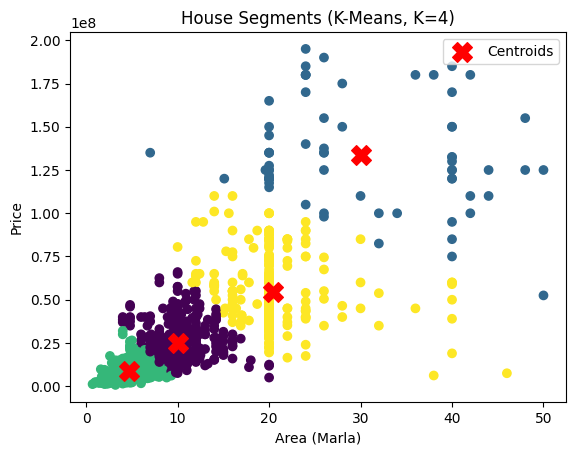

In [ ]:
plt.scatter(df['Area'],df['price'],c=df['Cluster'],cmap='viridis')
centers=scaler.inverse_transform(kMeans.cluster_centers_)
plt.scatter(centers[:,0],centers[:,1],c='red',marker='X',s=200,label='Centroids')
plt.xlabel('Area (Marla)')
plt.ylabel('Price')
plt.title('House Segments (K-Means, K=4)')
plt.legend()
plt.show()